# Fitness Data Analysis – Data Analyst Project

**Audience:** B.Tech 1st Year students (Data Analyst track)  
**Tools:** Python, pandas, matplotlib, seaborn

## Fitness Membership Analysis

A fitness center wants to understand members' fitness levels and the factors associated with better fitness scores. This analysis uses the supplied `fitness_clean.csv` dataset to examine attendance, workout hours, sleep, workout type, personal training, and fitness components.

> The dataset contains **250 fitness members and 14 columns**.


## 1. Business Problem

The fitness center wants to identify patterns in member fitness performance and understand which activities and habits are associated with higher fitness scores.

### Questions to Answer

1. What does the **Average Fitness Score** look like overall?
2. How are members distributed across **Fitness Bands**?
3. Does **Gym Attendance** relate to Average Fitness Score?
4. Does **Workout Hours per Week** relate to Average Fitness Score?
5. Which fitness component—**Strength, Endurance, or Flexibility**—has the strongest relationship with Average Fitness Score?
6. Does Average Fitness Score differ by **Workout Type, Gender, Membership Plan, and Personal Trainer**?


## 2. Import Libraries

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 100


## 3. Load and Inspect the Data

The supplied dataset is embedded in this notebook so the project remains self-contained.

In [ ]:
from io import StringIO

csv_data = 'Member_ID,Gender,Workout_Type,Membership_Plan,Gym_Attendance_Pct,Workout_Hours_Per_Week,Sleep_Hours,Personal_Trainer,Strength_Score,Endurance_Score,Flexibility_Score,Average_Score,Fitness_Band,Attendance_Band\nM1088,Male,Yoga,Monthly,73.3,6.2,6.0,No,58.0,67.0,65.0,63.3,Good,60-75%\nM1038,Male,HIIT,Monthly,86.8,8.8,6.4,No,72.0,77.0,80.0,76.3,Excellent,75-90%\nM1188,Male,Yoga,Monthly,78.7,4.9,7.9,No,66.0,55.0,62.0,61.0,Good,75-90%\nM1108,Male,Strength_Training,Monthly,63.9,9.3,6.2,Yes,69.0,46.0,84.0,66.3,Good,60-75%\nM1244,Female,HIIT,Monthly,90.3,5.8,8.4,No,72.0,59.0,64.0,65.0,Good,>90%\nM1229,Female,Zumba,Annual,91.5,7.2,5.9,Yes,71.0,60.0,84.0,71.7,Good,>90%\nM1040,Female,Strength_Training,Monthly,68.5,6.6,7.0,No,69.0,59.0,47.0,58.3,Average,60-75%\nM1003,Male,Cardio,Monthly,75.4,10.2,8.4,No,66.0,78.0,89.0,77.7,Excellent,75-90%\nM1095,Female,Cardio,Annual,62.2,6.4,9.0,Yes,50.0,58.0,61.0,56.3,Average,60-75%\nM1068,Male,Zumba,Annual,83.8,6.4,7.5,No,55.0,70.0,64.0,63.0,Good,75-90%\nM1240,Male,HIIT,Annual,84.1,8.1,6.5,No,62.0,64.0,69.0,65.0,Good,75-90%\nM1074,Female,HIIT,Annual,89.3,6.0,7.1,No,72.0,80.0,76.0,76.0,Excellent,75-90%\nM1139,Male,Strength_Training,Monthly,86.2,8.2,7.4,No,76.0,53.0,59.0,62.7,Good,75-90%\nM1228,Female,Cardio,Annual,72.3,5.4,7.1,No,58.0,60.0,65.0,61.0,Good,60-75%\nM1031,Female,Strength_Training,Annual,75.6,12.3,7.1,No,77.0,64.0,69.0,70.0,Good,75-90%\nM1164,Male,Yoga,Monthly,77.4,4.6,6.1,No,68.0,64.0,77.0,69.7,Good,75-90%\nM1160,Female,Strength_Training,Annual,76.0,1.0,5.7,No,55.0,47.0,52.0,51.3,Average,75-90%\nM1021,Female,Yoga,Annual,73.0,6.9,7.4,No,46.0,42.0,63.0,50.3,Average,60-75%\nM1152,Female,Strength_Training,Monthly,73.2,5.9,7.1,No,59.0,67.0,55.0,60.3,Good,60-75%\nM1230,Female,HIIT,Monthly,66.5,1.7,5.6,No,43.0,42.0,52.0,45.7,At Risk,60-75%\nM1107,Female,HIIT,Monthly,73.5,6.5,6.3,No,62.0,64.0,57.0,61.0,Good,60-75%\nM1091,Female,Strength_Training,Annual,74.2,3.1,7.5,No,53.0,50.0,61.0,54.7,Average,60-75%\nM1226,Female,Cardio,Annual,63.9,6.3,6.6,No,60.0,53.0,68.0,60.3,Good,60-75%\nM1017,Female,Cardio,Annual,74.1,6.1,7.3,No,59.0,75.0,65.0,66.3,Good,60-75%\nM1203,Female,Strength_Training,Annual,66.1,4.8,5.7,No,62.0,73.0,65.0,66.7,Good,60-75%\nM1105,Male,HIIT,Monthly,73.9,5.6,6.7,No,73.0,80.0,75.0,76.0,Excellent,60-75%\nM1233,Male,Strength_Training,Annual,56.3,6.9,5.4,No,54.0,57.0,59.0,56.7,Average,<60%\nM1161,Female,Zumba,Annual,72.3,10.4,6.2,No,72.0,78.0,81.0,77.0,Excellent,60-75%\nM1200,Female,HIIT,Monthly,89.8,3.0,5.5,No,80.0,76.0,68.0,74.7,Good,75-90%\nM1185,Female,Cardio,Monthly,76.4,8.5,5.1,No,65.0,63.0,61.0,63.0,Good,75-90%\nM1076,Male,HIIT,Monthly,66.1,6.5,6.6,No,65.0,74.0,59.0,66.0,Good,60-75%\nM1084,Male,HIIT,Annual,96.3,8.7,6.3,No,77.0,76.0,78.0,77.0,Excellent,>90%\nM1028,Male,HIIT,Annual,68.1,1.0,7.2,No,40.0,36.0,39.0,38.3,At Risk,60-75%\nM1098,Male,Zumba,Annual,76.3,8.6,8.7,No,78.0,72.0,71.0,73.7,Good,75-90%\nM1061,Male,Zumba,Annual,71.7,9.3,7.4,No,50.0,69.0,74.0,64.3,Good,60-75%\nM1246,Female,Yoga,Annual,59.1,1.0,5.1,No,62.0,44.0,52.0,52.7,Average,<60%\nM1205,Female,HIIT,Annual,96.7,5.5,5.8,No,50.0,64.0,55.0,56.3,Average,>90%\nM1223,Female,HIIT,Annual,76.7,7.8,6.3,Yes,58.0,76.0,73.0,69.0,Good,75-90%\nM1103,Male,Yoga,Monthly,62.2,8.1,7.4,No,47.0,53.0,66.0,55.3,Average,60-75%\nM1199,Male,HIIT,Monthly,75.4,8.2,7.3,Yes,56.0,74.0,73.0,67.7,Good,75-90%\nM1149,Male,Cardio,Annual,59.6,6.9,5.6,No,47.0,62.0,52.0,53.7,Average,<60%\nM1058,Male,HIIT,Monthly,68.7,5.5,6.6,Yes,64.0,71.0,70.0,68.3,Good,60-75%\nM1235,Male,Zumba,Annual,67.9,8.5,6.4,Yes,74.0,57.0,80.0,70.3,Good,60-75%\nM1194,Female,HIIT,Annual,71.7,5.5,6.5,No,54.0,48.0,63.0,55.0,Average,60-75%\nM1239,Male,HIIT,Annual,79.9,8.0,8.3,No,65.0,75.0,73.0,71.0,Good,75-90%\nM1078,Male,Zumba,Annual,73.5,9.0,4.9,No,75.0,58.0,67.0,66.7,Good,60-75%\nM1178,Male,HIIT,Monthly,66.2,10.0,8.1,No,67.0,57.0,51.0,58.3,Average,60-75%\nM1001,Male,Cardio,Monthly,75.4,8.6,7.7,No,53.0,58.0,74.0,61.7,Good,75-90%\nM1220,Female,Cardio,Annual,79.4,8.2,7.1,Yes,73.0,72.0,86.0,77.0,Excellent,75-90%\nM1196,Female,Zumba,Annual,64.3,2.8,8.2,No,44.0,57.0,58.0,53.0,Average,60-75%\nM1099,Female,Cardio,Monthly,77.9,5.1,6.1,No,62.0,55.0,66.0,61.0,Good,75-90%\nM1120,Male,HIIT,Annual,82.2,7.8,6.2,Yes,69.0,69.0,84.0,74.0,Good,75-90%\nM1075,Male,HIIT,Annual,57.5,9.8,6.7,No,65.0,62.0,72.0,66.3,Good,<60%\nM1176,Male,HIIT,Annual,78.8,8.8,7.3,Yes,71.0,69.0,76.0,72.0,Good,75-90%\nM1080,Female,HIIT,Annual,62.8,6.3,6.8,No,48.0,50.0,68.0,55.3,Average,60-75%\nM1192,Female,Cardio,Monthly,71.2,9.0,4.8,Yes,70.0,81.0,63.0,71.3,Good,60-75%\nM1236,Female,Zumba,Annual,76.4,6.3,5.6,No,51.0,61.0,62.0,58.0,Average,75-90%\nM1122,Male,Zumba,Annual,91.1,4.1,7.6,No,58.0,49.0,60.0,55.7,Average,>90%\nM1123,Female,Strength_Training,Monthly,40.0,3.0,5.5,Yes,42.0,36.0,32.0,36.7,At Risk,<60%\nM1141,Male,Zumba,Monthly,76.0,3.6,8.4,Yes,63.0,45.0,65.0,57.7,Average,75-90%\nM1037,Female,Zumba,Monthly,63.3,3.5,7.2,Yes,44.0,46.0,65.0,51.7,Average,60-75%\nM1208,Male,Yoga,Monthly,55.0,8.3,7.2,No,66.0,54.0,61.0,60.3,Good,<60%\nM1008,Female,HIIT,Annual,76.2,7.6,7.1,Yes,73.0,71.0,73.0,72.3,Good,75-90%\nM1081,Female,Zumba,Monthly,81.4,3.9,7.1,Yes,56.0,57.0,63.0,58.7,Average,75-90%\nM1036,Female,HIIT,Monthly,80.5,10.6,6.6,No,76.0,84.0,76.0,78.7,Excellent,75-90%\nM1201,Female,HIIT,Annual,95.9,6.4,7.7,No,61.0,65.0,81.0,69.0,Good,>90%\nM1112,Male,Zumba,Monthly,86.2,4.6,5.5,No,51.0,62.0,57.0,56.7,Average,75-90%\nM1124,Male,Strength_Training,Monthly,96.6,4.7,7.0,No,66.0,53.0,65.0,61.3,Good,>90%\nM1035,Female,Cardio,Annual,96.2,9.4,7.5,No,64.0,73.0,83.0,73.3,Good,>90%\nM1094,Female,Cardio,Annual,73.9,9.2,7.7,No,69.0,78.0,74.0,73.7,Good,60-75%\nM1225,Male,Zumba,Monthly,66.1,7.7,4.9,No,46.0,62.0,74.0,60.7,Good,60-75%\nM1238,Female,HIIT,Monthly,51.5,3.4,7.3,Yes,60.0,60.0,53.0,57.7,Average,<60%\nM1113,Female,Strength_Training,Monthly,64.4,5.0,5.8,No,54.0,50.0,55.0,53.0,Average,60-75%\nM1177,Male,Yoga,Monthly,73.4,7.5,7.0,No,63.0,58.0,69.0,63.3,Good,60-75%\nM1119,Male,Strength_Training,Annual,61.6,10.1,5.0,Yes,83.0,72.0,88.0,81.0,Excellent,60-75%\nM1117,Female,Zumba,Annual,84.5,8.8,7.3,No,59.0,54.0,59.0,57.3,Average,75-90%\nM1030,Female,Strength_Training,Monthly,81.8,7.9,5.2,Yes,73.0,83.0,87.0,81.0,Excellent,75-90%\nM1052,Male,HIIT,Monthly,100.0,5.9,9.0,Yes,59.0,73.0,65.0,65.7,Good,>90%\nM1147,Male,HIIT,Monthly,98.5,8.3,7.0,Yes,79.0,78.0,83.0,80.0,Excellent,>90%\nM1158,Female,HIIT,Monthly,100.0,1.7,6.6,No,87.0,68.0,69.0,74.7,Good,>90%\nM1050,Male,Strength_Training,Annual,89.7,12.4,5.6,No,84.0,85.0,91.0,86.7,Excellent,75-90%\nM1047,Male,Cardio,Annual,85.5,4.6,6.4,Yes,60.0,61.0,52.0,57.7,Average,75-90%\nM1134,Male,Zumba,Monthly,73.3,4.5,6.6,Yes,52.0,68.0,77.0,65.7,Good,60-75%\nM1165,Male,Cardio,Monthly,75.8,9.7,6.7,No,62.0,67.0,61.0,63.3,Good,75-90%\nM1125,Female,Strength_Training,Monthly,62.9,4.5,6.9,Yes,53.0,51.0,56.0,53.3,Average,60-75%\nM1138,Female,Yoga,Annual,79.3,1.0,8.4,No,46.0,60.0,64.0,56.7,Average,75-90%\nM1073,Male,Cardio,Monthly,62.8,3.7,6.8,No,59.0,72.0,59.0,63.3,Good,60-75%\nM1014,Female,Cardio,Annual,59.9,7.9,7.3,No,51.0,62.0,51.0,54.7,Average,<60%\nM1083,Male,Yoga,Monthly,65.8,9.6,6.2,No,71.0,60.0,70.0,67.0,Good,60-75%\nM1213,Male,Yoga,Monthly,93.1,5.7,6.4,No,61.0,42.0,71.0,58.0,Average,>90%\nM1011,Female,Strength_Training,Monthly,79.3,9.1,7.1,Yes,64.0,68.0,72.0,68.0,Good,75-90%\nM1242,Female,Strength_Training,Annual,83.9,7.3,6.4,No,60.0,68.0,74.0,67.3,Good,75-90%\nM1069,Female,Strength_Training,Monthly,73.0,3.6,6.5,Yes,56.0,48.0,63.0,55.7,Average,60-75%\nM1157,Male,Strength_Training,Monthly,99.5,8.6,5.0,No,80.0,80.0,72.0,77.3,Excellent,>90%\nM1039,Male,Zumba,Monthly,75.0,4.2,8.7,Yes,60.0,67.0,71.0,66.0,Good,60-75%\nM1049,Female,Yoga,Monthly,79.8,4.2,7.5,Yes,64.0,60.0,69.0,64.3,Good,75-90%\nM1250,Male,Zumba,Monthly,53.0,3.0,6.8,No,50.0,33.0,48.0,43.7,At Risk,<60%\nM1005,Female,Zumba,Monthly,71.0,1.0,7.3,No,52.0,41.0,59.0,50.7,Average,60-75%\nM1169,Male,HIIT,Annual,67.7,6.9,5.8,No,52.0,53.0,51.0,52.0,Average,60-75%\nM1012,Male,Strength_Training,Monthly,74.9,10.9,7.9,Yes,69.0,65.0,80.0,71.3,Good,60-75%\nM1077,Male,Strength_Training,Annual,81.8,7.4,7.4,Yes,60.0,66.0,60.0,62.0,Good,75-90%\nM1067,Male,HIIT,Monthly,62.1,6.6,7.1,No,63.0,57.0,69.0,63.0,Good,60-75%\nM1191,Female,Strength_Training,Annual,56.2,4.0,7.5,No,59.0,41.0,57.0,52.3,Average,<60%\nM1057,Male,Strength_Training,Annual,75.4,4.5,6.3,No,64.0,59.0,57.0,60.0,Good,75-90%\nM1066,Male,Strength_Training,Annual,66.1,7.4,6.9,No,67.0,46.0,74.0,62.3,Good,60-75%\nM1070,Male,Strength_Training,Monthly,84.8,6.4,6.9,No,67.0,64.0,66.0,65.7,Good,75-90%\nM1227,Male,Yoga,Annual,70.1,5.1,6.0,No,58.0,51.0,54.0,54.3,Average,60-75%\nM1135,Male,HIIT,Monthly,69.8,6.4,7.8,No,68.0,69.0,73.0,70.0,Good,60-75%\nM1210,Male,HIIT,Monthly,73.0,5.2,6.5,Yes,58.0,70.0,75.0,67.7,Good,60-75%\nM1006,Female,Cardio,Monthly,77.9,3.4,4.0,Yes,60.0,60.0,50.0,56.7,Average,75-90%\nM1020,Male,HIIT,Annual,85.8,5.4,6.3,No,60.0,74.0,71.0,68.3,Good,75-90%\nM1024,Male,HIIT,Annual,79.0,6.5,6.0,Yes,72.0,73.0,70.0,71.7,Good,75-90%\nM1186,Male,Zumba,Annual,82.8,7.9,7.1,No,62.0,64.0,71.0,65.7,Good,75-90%\nM1180,Male,Cardio,Monthly,58.5,5.5,8.5,No,63.0,53.0,56.0,57.3,Average,<60%\nM1043,Male,Strength_Training,Annual,91.1,3.9,5.7,No,70.0,64.0,68.0,67.3,Good,>90%\nM1151,Male,Cardio,Monthly,100.0,2.8,8.1,No,73.0,62.0,67.0,67.3,Good,>90%\nM1051,Female,Yoga,Monthly,76.5,7.9,5.8,Yes,55.0,55.0,69.0,59.7,Average,75-90%\nM1116,Female,Zumba,Monthly,88.1,8.7,8.5,No,64.0,74.0,83.0,73.7,Good,75-90%\nM1241,Female,Strength_Training,Monthly,60.5,6.6,7.2,Yes,65.0,55.0,75.0,65.0,Good,60-75%\nM1082,Female,Yoga,Annual,69.1,3.3,6.3,No,45.0,59.0,66.0,56.7,Average,60-75%\nM1234,Male,HIIT,Monthly,75.4,11.0,7.4,Yes,71.0,67.0,74.0,70.7,Good,75-90%\nM1019,Female,Strength_Training,Annual,56.2,10.5,6.5,No,58.0,53.0,65.0,58.7,Average,<60%\nM1190,Male,Zumba,Monthly,75.4,4.1,6.1,Yes,45.0,55.0,58.0,52.7,Average,75-90%\nM1109,Male,Strength_Training,Annual,79.0,8.3,6.5,No,55.0,67.0,67.0,63.0,Good,75-90%\nM1211,Male,Strength_Training,Monthly,66.3,6.2,5.3,No,61.0,61.0,58.0,60.0,Good,60-75%\nM1128,Female,Zumba,Monthly,61.8,3.5,7.2,No,59.0,47.0,66.0,57.3,Average,60-75%\nM1140,Female,Strength_Training,Monthly,86.6,4.4,7.5,No,64.0,61.0,64.0,63.0,Good,75-90%\nM1221,Male,Zumba,Monthly,68.6,7.1,6.3,Yes,81.0,74.0,83.0,79.3,Excellent,60-75%\nM1181,Male,Cardio,Monthly,82.8,1.9,5.1,No,45.0,62.0,52.0,53.0,Average,75-90%\nM1115,Female,Cardio,Monthly,77.9,4.0,4.5,No,64.0,63.0,57.0,61.3,Good,75-90%\nM1184,Female,Zumba,Annual,71.6,6.4,6.9,Yes,62.0,58.0,63.0,61.0,Good,60-75%\nM1216,Male,Yoga,Annual,83.6,6.5,7.1,No,65.0,62.0,73.0,66.7,Good,75-90%\nM1249,Female,Strength_Training,Annual,85.2,4.7,6.3,No,69.0,52.0,60.0,60.3,Good,75-90%\nM1016,Male,Yoga,Monthly,85.0,7.2,6.7,No,51.0,59.0,69.0,59.7,Average,75-90%\nM1010,Male,Zumba,Monthly,64.3,6.4,6.8,Yes,63.0,62.0,64.0,63.0,Good,60-75%\nM1092,Male,Cardio,Monthly,99.2,8.4,7.3,No,62.0,74.0,65.0,67.0,Good,>90%\nM1041,Female,Strength_Training,Monthly,84.8,6.8,7.2,No,63.0,58.0,65.0,62.0,Good,75-90%\nM1121,Male,Strength_Training,Monthly,73.8,4.0,6.9,No,67.0,57.0,70.0,64.7,Good,60-75%\nM1145,Male,Zumba,Monthly,76.1,6.9,5.5,No,63.0,68.0,74.0,68.3,Good,75-90%\nM1044,Female,Cardio,Annual,86.1,5.5,6.8,Yes,56.0,74.0,66.0,65.3,Good,75-90%\nM1018,Male,Yoga,Monthly,77.3,11.6,6.6,Yes,67.0,73.0,85.0,75.0,Excellent,75-90%\nM1209,Male,Strength_Training,Monthly,64.4,8.9,5.5,No,64.0,59.0,70.0,64.3,Good,60-75%\nM1055,Male,HIIT,Annual,82.9,10.1,6.9,No,81.0,79.0,93.0,84.3,Excellent,75-90%\nM1007,Female,Yoga,Monthly,78.9,7.6,5.7,No,56.0,81.0,71.0,69.3,Good,75-90%\nM1248,Female,Strength_Training,Monthly,61.0,3.7,6.5,No,55.0,48.0,43.0,48.7,At Risk,60-75%\nM1143,Male,Cardio,Annual,54.9,7.3,8.8,Yes,47.0,59.0,64.0,56.7,Average,<60%\nM1136,Male,Zumba,Annual,79.4,3.6,6.8,No,72.0,72.0,82.0,75.3,Excellent,75-90%\nM1079,Male,Cardio,Monthly,75.1,5.8,7.0,Yes,55.0,55.0,61.0,57.0,Average,75-90%\nM1237,Female,HIIT,Monthly,88.0,6.2,6.1,No,64.0,79.0,72.0,71.7,Good,75-90%\nM1111,Male,Yoga,Annual,78.2,7.8,7.3,No,61.0,58.0,71.0,63.3,Good,75-90%\nM1032,Male,HIIT,Annual,75.9,7.3,8.2,No,61.0,66.0,67.0,64.7,Good,75-90%\nM1142,Male,HIIT,Annual,73.6,3.6,7.3,Yes,56.0,65.0,57.0,59.3,Average,60-75%\nM1155,Male,Cardio,Annual,72.3,8.0,6.1,No,61.0,54.0,79.0,64.7,Good,60-75%\nM1009,Male,Cardio,Monthly,75.9,7.9,8.1,Yes,73.0,58.0,73.0,68.0,Good,75-90%\nM1232,Female,Cardio,Monthly,63.9,2.2,5.1,No,60.0,64.0,67.0,63.7,Good,60-75%\nM1148,Female,HIIT,Annual,89.2,2.7,6.4,Yes,61.0,73.0,73.0,69.0,Good,75-90%\nM1189,Male,Strength_Training,Annual,74.6,13.5,6.7,No,89.0,79.0,84.0,84.0,Excellent,60-75%\nM1231,Male,Zumba,Monthly,65.4,6.9,5.5,No,55.0,62.0,70.0,62.3,Good,60-75%\nM1195,Female,Zumba,Monthly,80.3,8.5,7.0,Yes,68.0,75.0,81.0,74.7,Good,75-90%\nM1198,Male,Yoga,Annual,69.4,9.8,6.2,No,65.0,75.0,81.0,73.7,Good,60-75%\nM1130,Male,Strength_Training,Annual,69.3,7.0,7.2,No,65.0,48.0,66.0,59.7,Average,60-75%\nM1022,Male,Strength_Training,Annual,75.4,5.3,5.6,No,61.0,60.0,69.0,63.3,Good,75-90%\nM1224,Male,Cardio,Monthly,77.0,6.4,5.8,Yes,59.0,70.0,68.0,65.7,Good,75-90%\nM1174,Male,Cardio,Monthly,67.6,6.2,6.4,Yes,67.0,70.0,75.0,70.7,Good,60-75%\nM1087,Male,Cardio,Annual,61.0,8.6,6.5,No,58.0,73.0,71.0,67.3,Good,60-75%\nM1062,Male,Cardio,Monthly,84.0,7.1,6.9,No,56.0,54.0,55.0,55.0,Average,75-90%\nM1064,Female,Yoga,Monthly,57.4,6.4,6.6,Yes,53.0,39.0,53.0,48.3,At Risk,<60%\nM1197,Male,Strength_Training,Annual,80.9,3.6,5.9,Yes,81.0,76.0,79.0,78.7,Excellent,75-90%\nM1175,Male,Zumba,Monthly,75.4,8.1,7.9,No,73.0,64.0,64.0,67.0,Good,75-90%\nM1063,Female,Strength_Training,Monthly,76.0,6.6,6.6,No,65.0,50.0,65.0,60.0,Good,75-90%\nM1129,Male,Yoga,Monthly,90.5,2.9,6.8,Yes,55.0,50.0,67.0,57.3,Average,>90%\nM1100,Male,Yoga,Annual,80.8,7.0,6.6,Yes,73.0,78.0,92.0,81.0,Excellent,75-90%\nM1034,Male,Cardio,Monthly,60.5,9.5,6.6,Yes,68.0,61.0,59.0,62.7,Good,60-75%\nM1153,Male,Cardio,Monthly,93.3,9.7,7.0,No,69.0,74.0,73.0,72.0,Good,>90%\nM1144,Female,Strength_Training,Annual,75.4,3.9,5.1,Yes,60.0,76.0,76.0,70.7,Good,75-90%\nM1086,Female,Yoga,Annual,61.8,5.6,6.8,No,56.0,60.0,59.0,58.3,Average,60-75%\nM1187,Male,Yoga,Annual,78.6,8.0,6.8,No,66.0,64.0,58.0,62.7,Good,75-90%\nM1026,Male,Yoga,Annual,66.0,9.1,5.3,No,41.0,54.0,63.0,52.7,Average,60-75%\nM1065,Male,HIIT,Annual,75.4,5.4,7.0,No,65.0,55.0,59.0,59.7,Average,75-90%\nM1089,Male,Cardio,Annual,73.8,8.7,7.1,No,79.0,80.0,68.0,75.7,Excellent,60-75%\nM1243,Male,Cardio,Monthly,49.6,6.2,8.8,No,57.0,58.0,59.0,58.0,Average,<60%\nM1245,Male,Yoga,Annual,97.5,5.4,6.8,Yes,74.0,74.0,93.0,80.3,Excellent,>90%\nM1133,Male,Strength_Training,Monthly,84.6,4.9,6.8,No,65.0,59.0,66.0,63.3,Good,75-90%\nM1085,Female,Cardio,Monthly,60.1,4.2,7.2,No,54.0,62.0,66.0,60.7,Good,60-75%\nM1042,Male,Zumba,Annual,65.1,5.3,6.9,Yes,59.0,67.0,62.0,62.7,Good,60-75%\nM1156,Male,HIIT,Annual,74.6,8.3,6.1,No,62.0,70.0,66.0,66.0,Good,60-75%\nM1114,Male,Yoga,Monthly,82.6,3.7,7.9,Yes,67.0,60.0,65.0,64.0,Good,75-90%\nM1219,Male,Cardio,Annual,64.1,1.0,5.0,No,36.0,35.0,52.0,41.0,At Risk,60-75%\nM1104,Male,HIIT,Annual,71.7,8.4,7.6,No,51.0,66.0,68.0,61.7,Good,60-75%\nM1071,Male,Yoga,Monthly,91.4,5.8,8.9,No,71.0,81.0,77.0,76.3,Excellent,>90%\nM1056,Male,Strength_Training,Annual,80.8,5.1,8.2,Yes,74.0,72.0,78.0,74.7,Good,75-90%\nM1046,Male,Yoga,Monthly,89.3,3.0,7.3,Yes,73.0,75.0,80.0,76.0,Excellent,75-90%\nM1172,Male,Strength_Training,Annual,64.6,7.3,8.1,No,52.0,40.0,52.0,48.0,At Risk,60-75%\nM1215,Female,HIIT,Monthly,78.3,4.1,7.4,No,65.0,62.0,69.0,65.3,Good,75-90%\nM1097,Male,Cardio,Monthly,67.4,6.4,5.7,No,44.0,50.0,54.0,49.3,At Risk,60-75%\nM1015,Female,Strength_Training,Annual,78.6,3.9,6.0,No,64.0,54.0,67.0,61.7,Good,75-90%\nM1159,Female,Cardio,Annual,77.0,7.0,5.5,No,71.0,62.0,72.0,68.3,Good,75-90%\nM1025,Male,Yoga,Monthly,85.5,2.5,9.0,Yes,68.0,49.0,66.0,61.0,Good,75-90%\nM1002,Female,Strength_Training,Monthly,85.4,5.4,6.2,No,82.0,62.0,68.0,70.7,Good,75-90%\nM1146,Female,Strength_Training,Annual,94.8,7.6,7.2,No,68.0,71.0,66.0,68.3,Good,>90%\nM1150,Female,Strength_Training,Annual,88.0,9.9,8.5,Yes,76.0,71.0,82.0,76.3,Excellent,75-90%\nM1060,Male,Yoga,Monthly,64.8,2.7,6.9,Yes,50.0,60.0,62.0,57.3,Average,60-75%\nM1163,Male,Strength_Training,Monthly,69.4,6.4,6.8,Yes,63.0,59.0,59.0,60.3,Good,60-75%\nM1027,Female,Strength_Training,Monthly,75.4,3.0,6.1,No,63.0,67.0,64.0,64.7,Good,75-90%\nM1212,Male,HIIT,Monthly,87.1,1.5,5.7,No,59.0,54.0,72.0,61.7,Good,75-90%\nM1193,Female,Strength_Training,Monthly,77.9,6.6,6.9,No,55.0,53.0,60.0,56.0,Average,75-90%\nM1179,Male,Strength_Training,Annual,71.2,7.2,6.8,Yes,68.0,65.0,69.0,67.3,Good,60-75%\nM1029,Female,Yoga,Annual,78.6,7.8,6.7,No,61.0,64.0,64.0,63.0,Good,75-90%\nM1048,Female,Strength_Training,Annual,83.7,8.3,5.7,No,68.0,63.0,79.0,70.0,Good,75-90%\nM1204,Female,Cardio,Monthly,67.4,8.4,4.3,No,62.0,56.0,79.0,65.7,Good,60-75%\nM1053,Male,Strength_Training,Monthly,87.8,5.7,6.9,No,73.0,72.0,68.0,71.0,Good,75-90%\nM1118,Male,Cardio,Annual,43.7,5.6,7.9,No,53.0,46.0,53.0,50.7,Average,<60%\nM1023,Male,Strength_Training,Annual,75.0,5.6,6.6,Yes,72.0,52.0,76.0,66.7,Good,60-75%\nM1217,Male,Strength_Training,Annual,90.0,7.1,7.0,No,71.0,64.0,76.0,70.3,Good,75-90%\nM1202,Female,Yoga,Monthly,68.1,11.8,6.0,No,67.0,68.0,75.0,70.0,Good,60-75%\nM1045,Female,Yoga,Monthly,81.8,8.6,6.3,No,67.0,60.0,79.0,68.7,Good,75-90%\nM1182,Male,Strength_Training,Monthly,65.5,2.0,7.1,No,52.0,47.0,51.0,50.0,Average,60-75%\nM1033,Female,Cardio,Annual,96.1,3.7,6.5,Yes,62.0,68.0,69.0,66.3,Good,>90%\nM1072,Male,HIIT,Monthly,89.2,5.5,5.0,No,67.0,69.0,72.0,69.3,Good,75-90%\nM1166,Male,Strength_Training,Monthly,69.1,1.8,7.0,No,51.0,50.0,57.0,52.7,Average,60-75%\nM1059,Female,HIIT,Annual,68.8,7.8,7.0,Yes,68.0,60.0,75.0,67.7,Good,60-75%\nM1054,Female,HIIT,Monthly,51.8,8.0,6.4,No,51.0,56.0,53.0,53.3,Average,<60%\nM1218,Female,Cardio,Annual,95.6,1.6,7.4,No,68.0,54.0,70.0,64.0,Good,>90%\nM1207,Male,Strength_Training,Monthly,81.2,7.6,7.2,No,74.0,61.0,74.0,69.7,Good,75-90%\nM1154,Male,HIIT,Monthly,66.5,4.8,8.0,Yes,63.0,56.0,56.0,58.3,Average,60-75%\nM1206,Male,Strength_Training,Annual,86.7,4.4,5.1,No,69.0,66.0,65.0,66.7,Good,75-90%\nM1126,Male,Strength_Training,Monthly,71.1,1.0,5.5,No,58.0,47.0,46.0,50.3,Average,60-75%\nM1132,Male,Cardio,Monthly,91.0,9.3,6.8,No,88.0,97.0,83.0,89.3,Excellent,>90%\nM1004,Male,HIIT,Annual,67.5,1.8,8.1,No,56.0,49.0,54.0,53.0,Average,60-75%\nM1013,Male,Zumba,Annual,78.0,9.3,4.3,Yes,73.0,64.0,80.0,72.3,Good,75-90%\nM1167,Female,HIIT,Monthly,80.4,4.1,6.6,No,70.0,82.0,66.0,72.7,Good,75-90%\nM1093,Female,HIIT,Monthly,72.4,2.1,5.5,No,43.0,36.0,63.0,47.3,At Risk,60-75%\nM1110,Male,Strength_Training,Monthly,71.6,5.1,6.2,No,61.0,57.0,64.0,60.7,Good,60-75%\nM1173,Female,Yoga,Annual,64.0,3.2,6.7,No,52.0,52.0,64.0,56.0,Average,60-75%\nM1214,Male,Strength_Training,Annual,73.5,8.0,5.6,No,52.0,56.0,51.0,53.0,Average,60-75%\nM1127,Female,Cardio,Annual,81.3,5.5,9.0,No,55.0,59.0,74.0,62.7,Good,75-90%\nM1171,Female,HIIT,Annual,93.7,6.8,6.6,Yes,72.0,75.0,64.0,70.3,Good,>90%\nM1090,Female,Strength_Training,Monthly,59.8,7.0,6.8,No,59.0,49.0,44.0,50.7,Average,<60%\nM1106,Male,Cardio,Monthly,76.1,1.1,6.6,No,51.0,50.0,61.0,54.0,Average,75-90%\nM1168,Male,Yoga,Annual,79.7,7.7,6.6,No,65.0,68.0,80.0,71.0,Good,75-90%\nM1183,Female,Cardio,Monthly,65.8,6.8,6.1,No,59.0,72.0,72.0,67.7,Good,60-75%\nM1162,Female,Cardio,Monthly,76.8,7.9,7.7,No,64.0,54.0,63.0,60.3,Good,75-90%\nM1137,Male,Cardio,Monthly,67.3,6.9,7.5,No,53.0,55.0,64.0,57.3,Average,60-75%\nM1222,Male,Strength_Training,Annual,56.5,6.7,8.2,Yes,60.0,52.0,65.0,59.0,Average,<60%\nM1247,Male,Strength_Training,Monthly,55.0,2.5,7.1,No,50.0,48.0,54.0,50.7,Average,<60%\nM1101,Female,Strength_Training,Monthly,98.4,7.0,5.5,No,74.0,79.0,72.0,75.0,Excellent,>90%\nM1131,Female,Yoga,Annual,67.8,3.3,5.4,No,52.0,47.0,52.0,50.3,Average,60-75%\nM1102,Female,Yoga,Monthly,75.6,6.1,6.7,No,52.0,48.0,66.0,55.3,Average,75-90%\nM1170,Female,Cardio,Monthly,68.0,6.0,5.7,No,47.0,72.0,66.0,61.7,Good,60-75%\nM1096,Female,Zumba,Annual,66.5,5.5,6.9,No,43.0,54.0,59.0,52.0,Average,60-75%\n'
df = pd.read_csv(StringIO(csv_data))

print("Rows, Columns:", df.shape)
df.head()


In [ ]:
df.info()

In [ ]:
print("Missing values per column:")
print(df.isna().sum()[df.isna().sum() > 0])

print("\nDuplicate rows:", df.duplicated().sum())

df.describe().round(2)


**What we found:** the supplied file is already a clean fitness dataset. It contains 250 unique member records, no missing values, and the main numeric fitness variables are within the observed ranges. The next steps focus on validation, feature creation, and analysis.


## 4. Clean and Validate the Data

In [ ]:
clean = df.copy()

# Remove exact duplicate rows if any are present
clean = clean.drop_duplicates().reset_index(drop=True)

# Standardize text fields
text_cols = ["Gender", "Workout_Type", "Membership_Plan", "Personal_Trainer",
             "Fitness_Band", "Attendance_Band"]
for col in text_cols:
    clean[col] = clean[col].astype(str).str.strip()

# Validate numeric ranges
print("Attendance range:", clean["Gym_Attendance_Pct"].min(), "to", clean["Gym_Attendance_Pct"].max())
print("Workout hours range:", clean["Workout_Hours_Per_Week"].min(), "to", clean["Workout_Hours_Per_Week"].max())
print("Sleep hours range:", clean["Sleep_Hours"].min(), "to", clean["Sleep_Hours"].max())

print("Rows after cleaning:", len(clean))
print("Missing values left:", clean.isna().sum().sum())


## 5. Create New Columns (Feature Engineering)

The dataset already provides fitness and attendance bands. We also create a few useful analysis features:
- `Fitness_Component_Average` – average of Strength, Endurance and Flexibility.
- `Workout_Intensity_Group` – groups weekly workout hours into simple activity levels.


In [ ]:
clean["Fitness_Component_Average"] = (
    clean["Strength_Score"] +
    clean["Endurance_Score"] +
    clean["Flexibility_Score"]
) / 3

clean["Workout_Intensity_Group"] = pd.cut(
    clean["Workout_Hours_Per_Week"],
    bins=[0, 4, 8, np.inf],
    labels=["Low", "Moderate", "High"],
    include_lowest=True
)

clean[[
    "Member_ID", "Average_Score", "Fitness_Component_Average",
    "Workout_Hours_Per_Week", "Workout_Intensity_Group"
]].head()


## 6. Distribution of Average Fitness Score

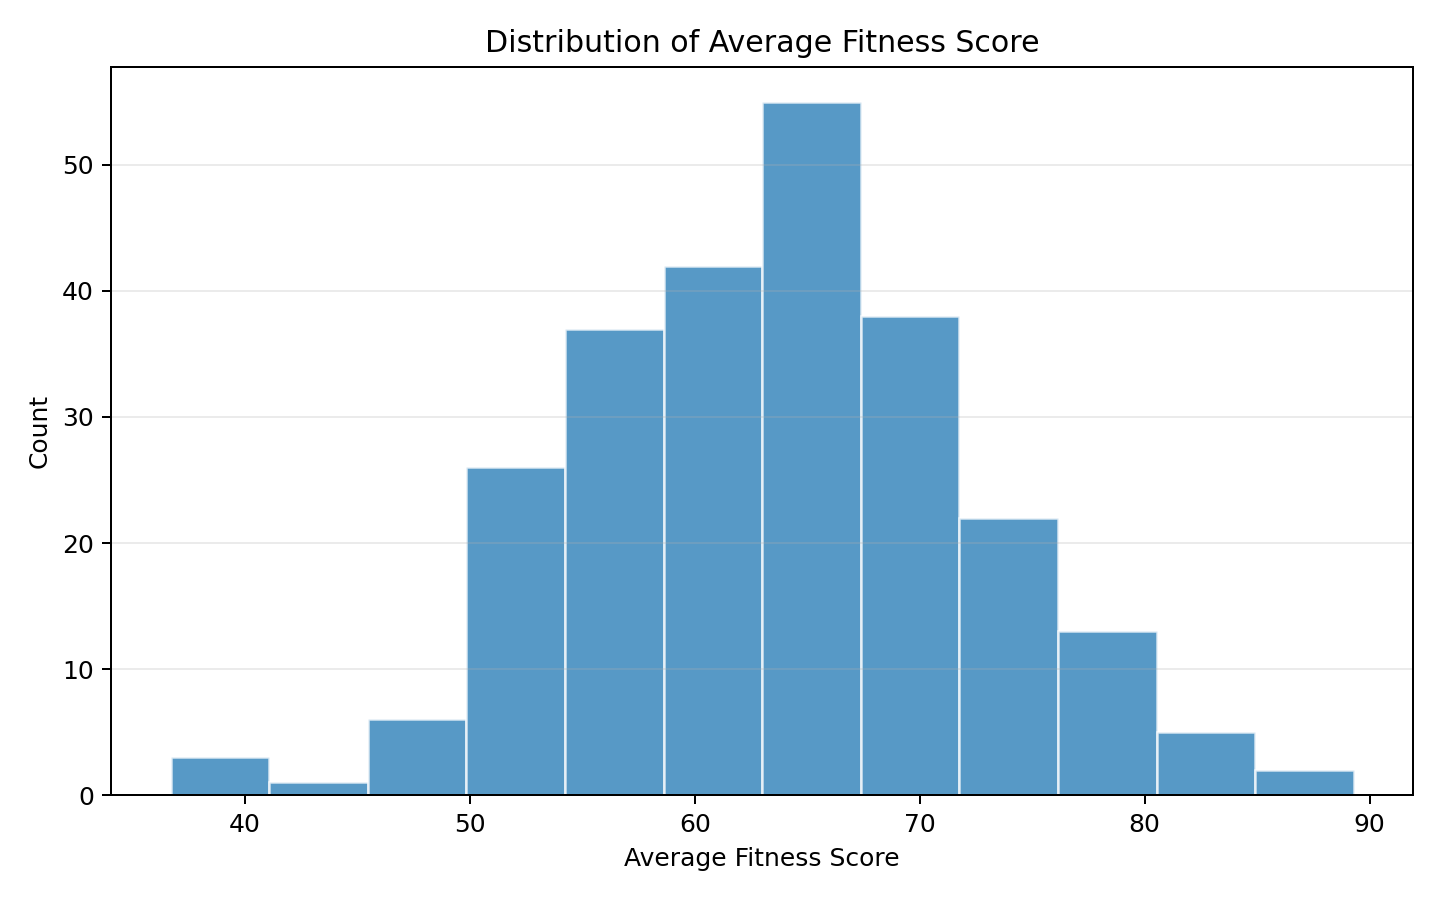

**Analysis:** Average Fitness Scores are concentrated around the low-to-mid 60s, with most members falling roughly between 55 and 75. The distribution has fewer members at the extreme low and high ends.


## 7. Members by Fitness Band

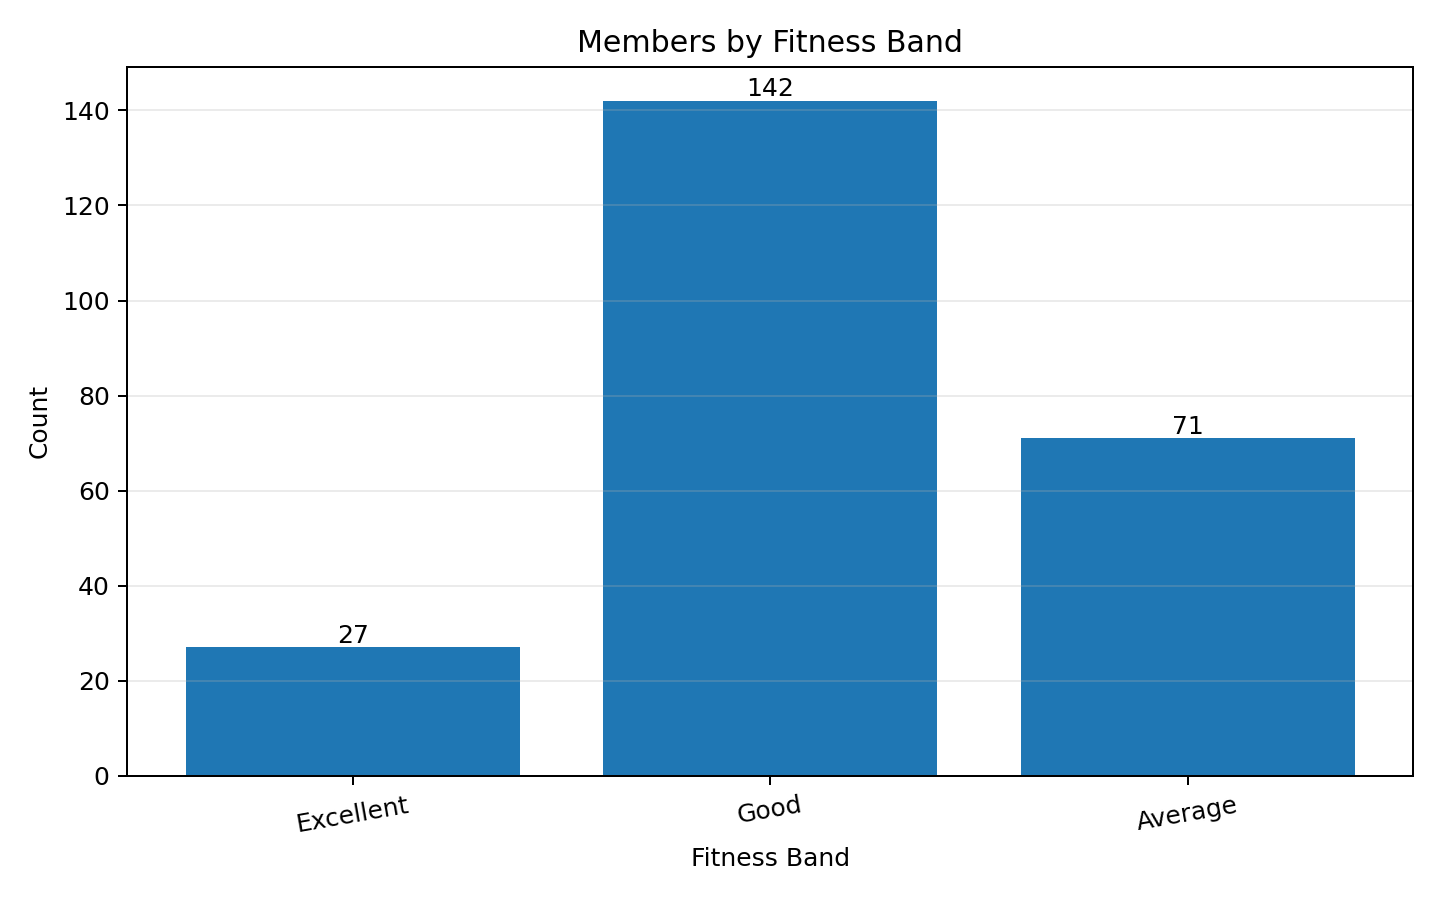

**Analysis:** The largest group is **Good** with 142 members, followed by **Average** with 71. There are 27 members in the **Excellent** band and 10 in the **At Risk** band.


## 8. Gym Attendance vs Average Fitness Score

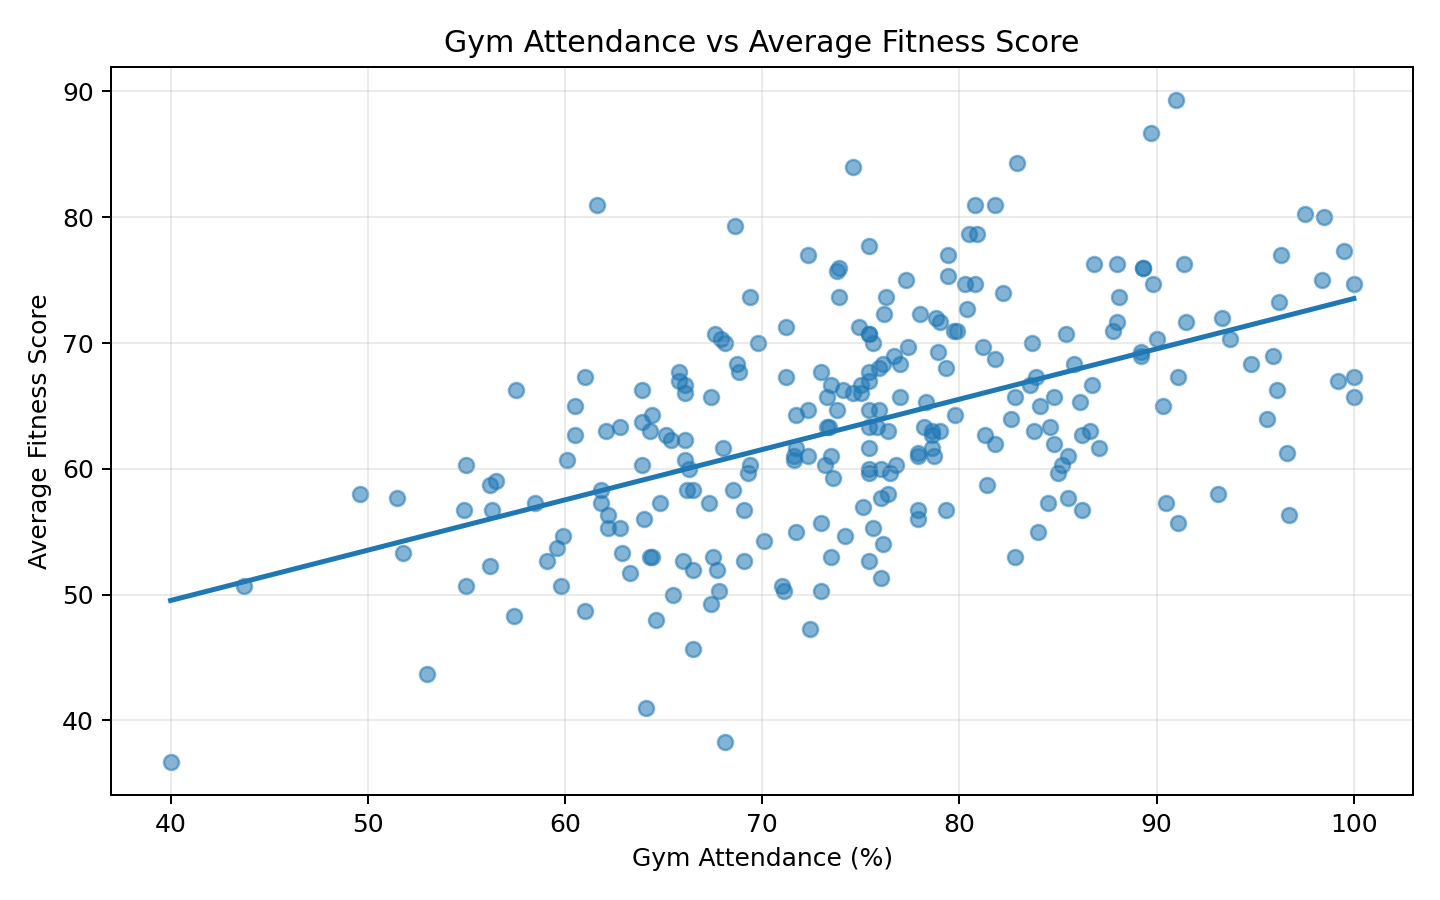

**Analysis:** The upward trend line shows a moderate positive relationship. Members with higher gym attendance generally tend to have higher fitness scores, although there is substantial variation between individual members.


## 9. Workout Hours vs Average Fitness Score

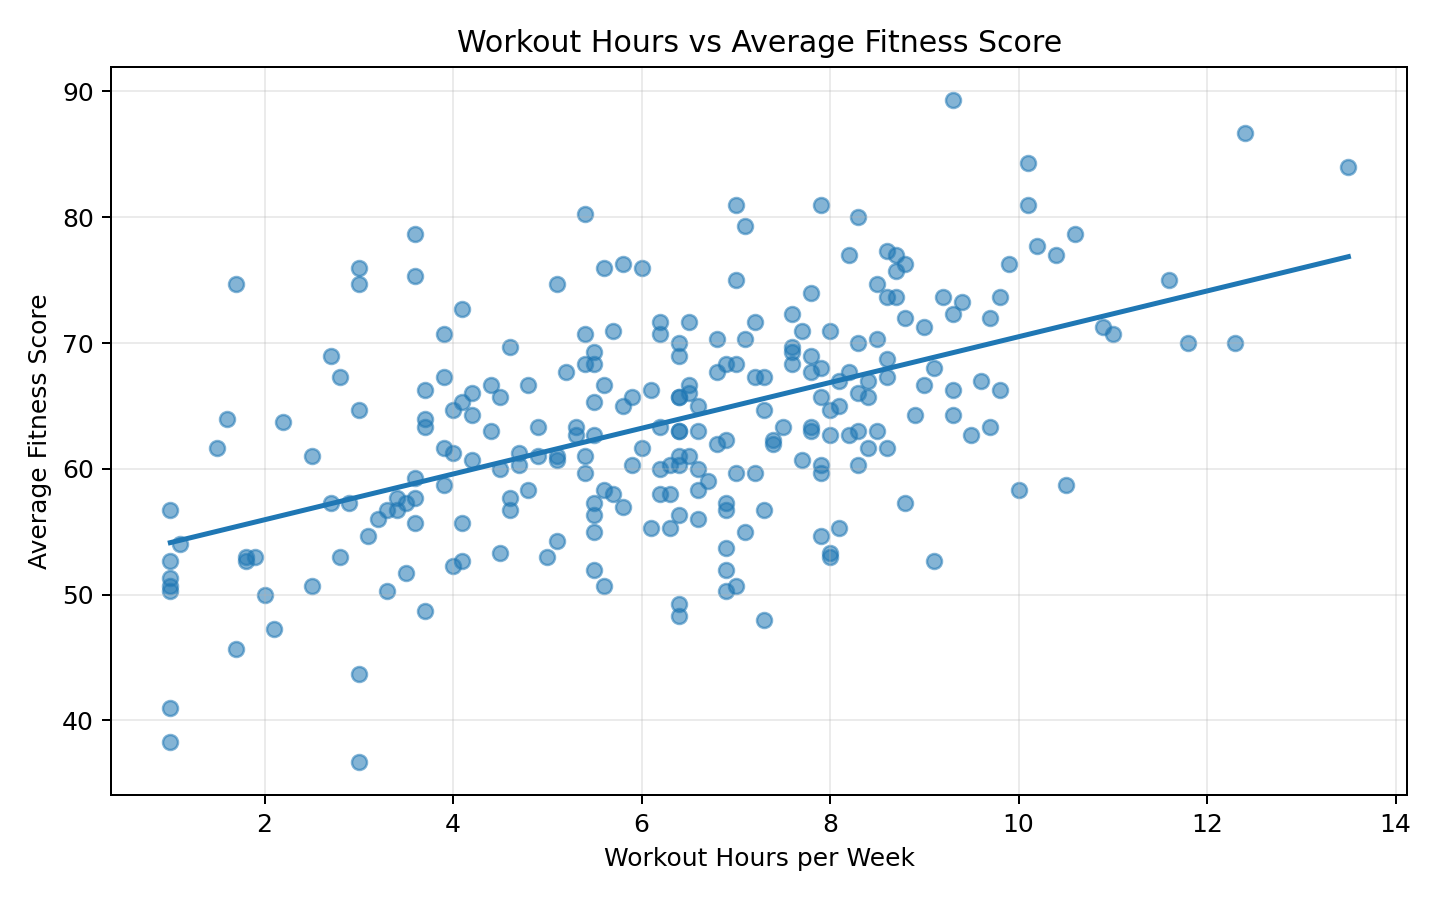

**Analysis:** Weekly workout hours also show a positive relationship with fitness score. More training time is generally associated with better fitness, but workout duration alone does not explain all differences between members.


## 10. Correlation Analysis

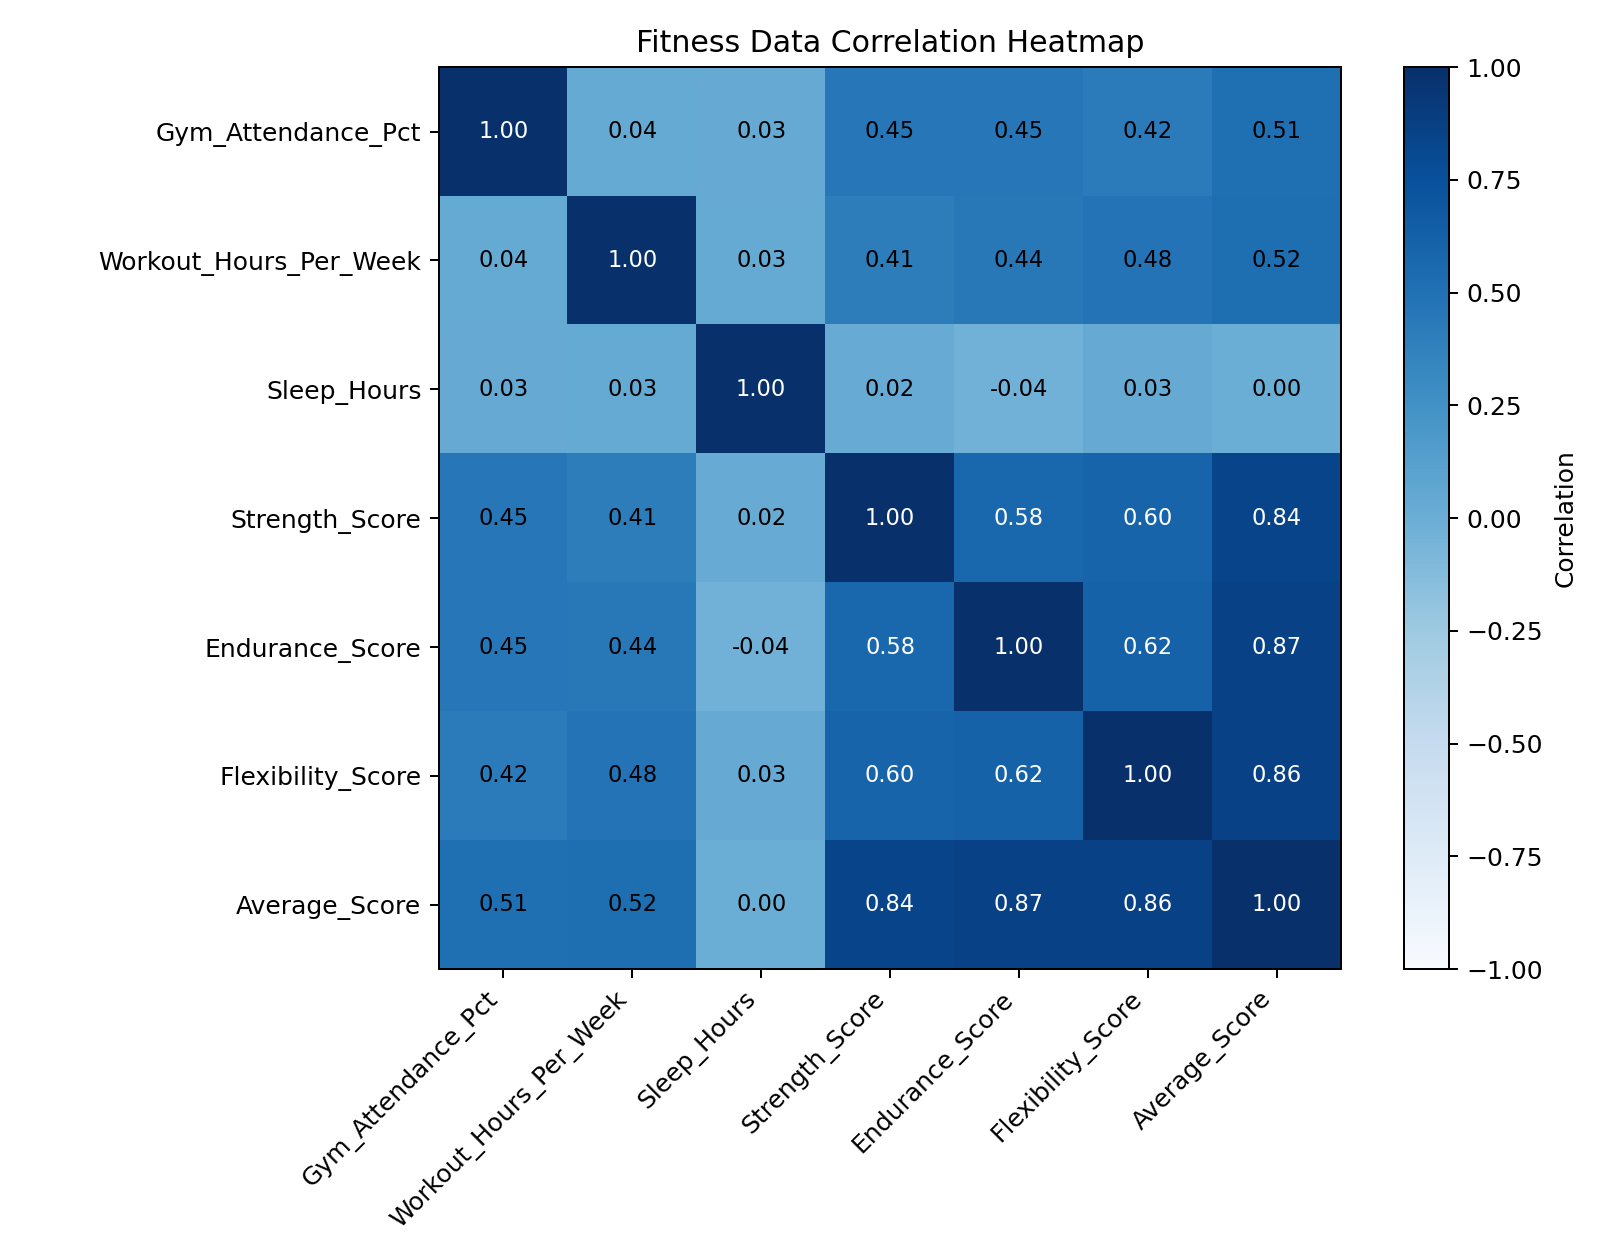

In [ ]:
corr = clean[[
    "Gym_Attendance_Pct", "Workout_Hours_Per_Week", "Sleep_Hours",
    "Strength_Score", "Endurance_Score", "Flexibility_Score",
    "Average_Score"
]].corr()

corr["Average_Score"].sort_values(ascending=False)


**Key correlation findings:**
- Endurance Score has the strongest relationship with Average Score: **0.87**.
- Flexibility Score is also strongly related: **0.86**.
- Strength Score has a strong relationship: **0.84**.
- Workout Hours and Gym Attendance have moderate positive relationships of about **0.52** and **0.51**.
- Sleep Hours has almost no linear relationship with Average Score in this dataset (**0.00**).

Correlation indicates association, not causation.


## 11. Average Fitness Score by Workout Type

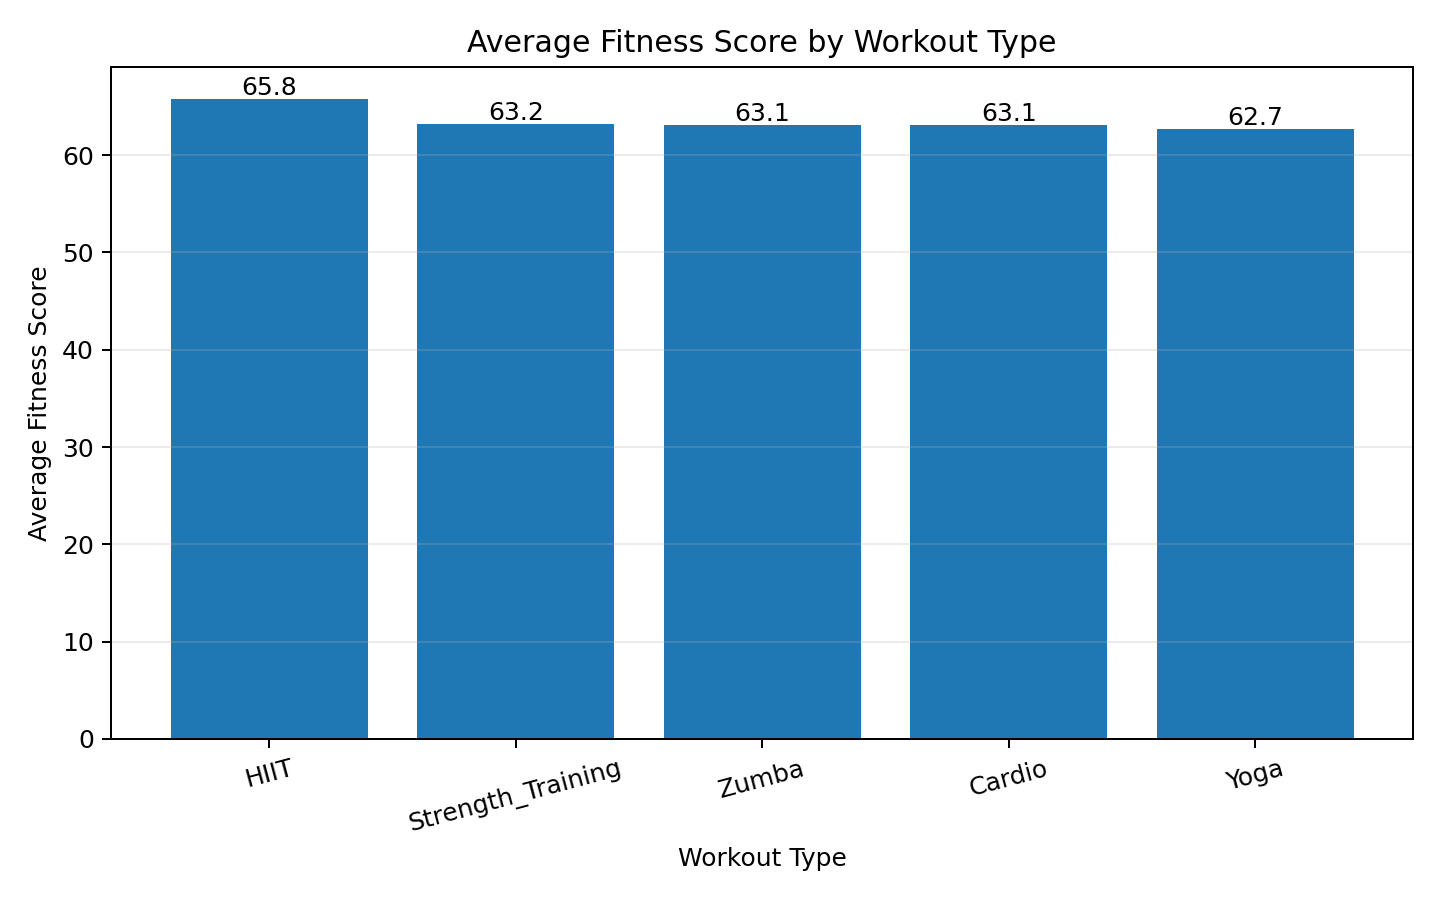

**Analysis:** HIIT has the highest average fitness score at about **65.8**. Strength Training, Zumba and Cardio are close to 63, while Yoga is about 62.7. The differences are relatively small.


## 12. Average Fitness Score by Gender

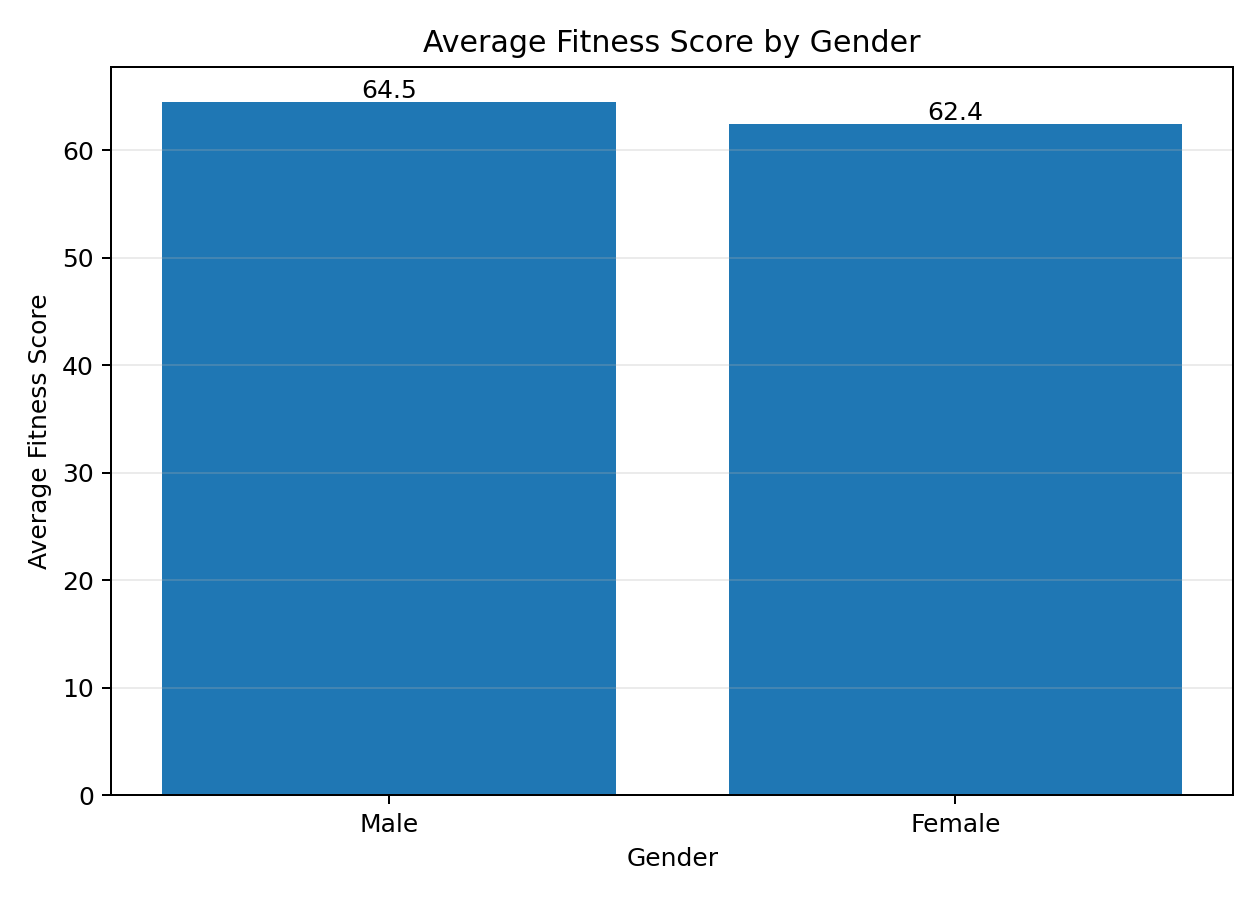

**Analysis:** The average score for male members is about **64.5**, compared with about **62.4** for female members. This difference should be interpreted as a descriptive result from this dataset rather than a general conclusion about gender and fitness.


## 13. Additional Group Analysis

In [ ]:
print("Average Fitness Score by Membership Plan:")
print(clean.groupby("Membership_Plan")["Average_Score"].mean().sort_values(ascending=False).round(2))

print("\nAverage Fitness Score by Personal Trainer:")
print(clean.groupby("Personal_Trainer")["Average_Score"].mean().sort_values(ascending=False).round(2))

print("\nFitness Band counts:")
print(clean["Fitness_Band"].value_counts())


## 14. Key Insights

1. **Good fitness is the most common outcome:** 142 of 250 members are in the Good band.
2. **Attendance matters:** Gym attendance has a moderate positive correlation (~0.51) with Average Fitness Score.
3. **Workout time matters:** Workout Hours per Week also has a moderate positive correlation (~0.52).
4. **Fitness components matter most:** Endurance, Flexibility and Strength have the strongest relationships with Average Score, with correlations of approximately 0.87, 0.86 and 0.84.
5. **HIIT has the highest average score:** Its average is approximately 65.8.
6. **Personal training is associated with higher scores:** Members with a trainer average about 66.0 versus 62.7 without one.
7. **Sleep is not strongly associated with the score in this dataset:** its linear correlation is approximately 0.00.


## 15. Conclusion

The analysis shows that fitness performance in this dataset is most closely associated with the three measured fitness components—Endurance, Flexibility and Strength. Attendance and weekly workout hours also show meaningful positive relationships with overall fitness.

The dataset can be used for further work such as member segmentation, fitness-score prediction, or building a dashboard for gym management.


## 16. Processed Data

The cleaned dataset used throughout this notebook is stored in the `clean` DataFrame. It includes the original 14 columns plus the engineered `Fitness_Component_Average` and `Workout_Intensity_Group` columns.

### Final shape
- **Rows:** 250
- **Original columns:** 14
- **Processed columns:** 16


In [ ]:
# View the processed dataset
clean.head(20)
